# Experiment 7: Decision Tree and Random Forest: A Comparative Classification Study
**Course:** UCS3512 – Machine Learning Laboratory  
**Department:** Computer Science and Engineering, SSN College of Engineering  
**Student Name:** Thushar TL  
**Register Number:** 312245001188  
**Semester:** V  
**Academic Year:** 2026–2027 (Odd) | **Batch:** 2024–2028

## 1. Aim and Objectives

### 1.1 Aim
To implement a **Decision Tree classifier** and extend it into a **Random Forest ensemble classifier** for diagnosing breast cancer tumors using the **Wisconsin Diagnostic Breast Cancer (WDBC) dataset**, to evaluate the impact of tree depth and hyperparameters on model variance and overfitting using **5-Fold Cross-Validation**, and to conduct a rigorous comparative study using multiple classification metrics, confusion matrices, and ROC-AUC curves.

### 1.2 Objectives
1. **Load and Prepare Data:** Load the 569 instances and 30 numerical attributes of the WDBC dataset and encode class labels (Malignant and Benign).
2. **Exploratory Data Analysis (EDA):** Analyze class balance, calculate statistical summaries, and identify highly collinear feature clusters (e.g. radius, perimeter, and area).
3. **Stratified Train-Test Splitting:** Partition the dataset into **80% Training (455 samples)** and **20% Testing (114 samples)** using stratified sampling.
4. **Decision Tree Hyperparameter Exploration:** Explore the influence of splitting criteria (`gini`, `entropy`), `max_depth`, `min_samples_split`, and `min_samples_leaf`.
5. **5-Fold Cross-Validation for Decision Tree:** Systematically evaluate hyperparameter configurations via 5-fold CV to generate **Table 1: Decision Tree Hyperparameter Evaluation**.
6. **Random Forest Classifier Implementation:** Construct the ensemble model exploring `n_estimators`, `max_depth`, `max_features`, and `bootstrap`.
7. **5-Fold Cross-Validation for Random Forest:** Evaluate hyperparameter configurations via 5-fold CV to generate **Table 2: Random Forest Hyperparameter Evaluation**.
8. **Performance Comparison Across Folds:** Build **Table 3: 5-Fold Cross-Validation Performance Comparison** reporting Fold 1 through Fold 5 and Average accuracy for both models.
9. **Held-Out Test Set Evaluation:** Evaluate both optimized models using Accuracy, Precision, Recall, F1-Score, Confusion Matrices, and ROC-AUC curves.
10. **In-Depth Overfitting and Generalization Analysis:** Answer all assigned observation questions regarding tree depth, variance reduction, and ensemble efficacy.

## 2. Theoretical Background

### 2.1 Decision Tree Classifier
A Decision Tree is a non-parametric supervised learning algorithm that recursively partitions the input feature space into rectangular regions parallel to the coordinate axes. At each internal node, the algorithm selects the feature $j$ and split threshold $t$ that maximize the reduction in impurity (Information Gain).

#### Impurity Measures:
1. **Gini Impurity:**
   $$I_G(p) = 1 - \sum_{k=1}^C p_k^2$$
   where $p_k$ is the proportion of samples belonging to class $k$ at that node.
2. **Entropy (Information Gain):**
   $$H(p) = - \sum_{k=1}^C p_k \log_2(p_k)$$

#### Inherent Limitation of Single Decision Trees:
Deep decision trees partition data until leaf nodes are nearly pure. While this yields nearly 100% training accuracy, it causes **high variance and severe overfitting**: small fluctuations in training samples produce radically different tree topologies that generalize poorly to unseen data.

---

### 2.2 Random Forest Classifier
Random Forest (Breiman, 2001) is an ensemble method designed to mitigate the high variance of individual decision trees through two core mechanisms:
1. **Bootstrap Aggregation (Bagging):** Given a dataset of size $N$, each of the $M$ trees is trained on an independently drawn bootstrap sample (drawn with replacement of size $N$). On average, each bootstrap sample contains approximately $63.2\%$ unique instances, while the remaining $36.8\%$ form the Out-Of-Bag (OOB) sample.
2. **Random Feature Subspace Selection:** At each node split within every tree, only a random subset of $m \le D$ features (typically $m = \sqrt{D}$) is considered as candidate split attributes.
3. **Majority Voting:** For classification, the final prediction is the mode of all individual tree predictions:
   $$\hat{y} = \text{mode} \left( h_1(x), h_2(x), \dots, h_M(x) \right)$$

#### Why Random Forest Reduces Variance:
If $M$ identically distributed (but not fully independent) trees each have variance $\sigma^2$ with pairwise correlation $\rho$, the variance of the ensemble average is:
$$\text{Var}(\bar{T}) = \rho \sigma^2 + \frac{1 - \rho}{M} \sigma^2$$
As $M \to \infty$, the second term approaches zero, leaving $\rho \sigma^2$. By randomly selecting a feature subset at each node split, Random Forest **decorrelates the trees** (substantially decreasing $\rho$), achieving significantly lower variance and superior generalization without increasing bias.

## 3. Implementation Step-by-Step

### Step 0: Library Imports and Setup
We import core scientific and ML modules from `sklearn`, `pandas`, `numpy`, and `matplotlib`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)

# Set global random state
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot configuration
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.edgecolor'] = '#333333'

print("Libraries imported successfully!")

Libraries imported successfully!


### Step 1: Loading the Dataset and Encoding Class Labels
We load the **Wisconsin Diagnostic Breast Cancer (WDBC)** dataset.
- Total samples: 569
- Total features: 30 numerical attributes (mean, standard error, and worst values for 10 nuclear characteristics: radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension).
- Target classes:
  - `0`: Malignant (M) – 212 samples (37.3%)
  - `1`: Benign (B) – 357 samples (62.7%)

In [2]:
# Load dataset
cancer = load_breast_cancer()
X = pd.DataFrame(cancer.data, columns=cancer.feature_names)
y = pd.Series(cancer.target, name="target") # 0 = malignant, 1 = benign

target_names = {0: 'Malignant', 1: 'Benign'}
y_labeled = y.map(target_names)

print(f"Dataset Shape: {X.shape[0]} samples, {X.shape[1]} features")
print("\nTarget Class Counts:")
print(pd.Series(y_labeled).value_counts())
print(f"Class Balance: {y.mean()*100:.2f}% Benign, {(1 - y.mean())*100:.2f}% Malignant")

# Verify missing values
print(f"Total Missing Values: {X.isnull().sum().sum()}")
X.head()

Dataset Shape: 569 samples, 30 features

Target Class Counts:
target
Benign       357
Malignant    212
Name: count, dtype: int64
Class Balance: 62.74% Benign, 37.26% Malignant
Total Missing Values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Step 2: Exploratory Data Analysis (EDA)
We conduct EDA to:
1. Visualize the target class balance.
2. Analyze feature correlations across all 30 variables.
3. Identify top collinear feature pairs.
4. Examine feature distributions separating malignant and benign tumors.

/tmp/ipykernel_9909/2986879483.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y_labeled, y=X['mean concave points'], ax=axes[1], palette=['#c0392b', '#27ae60'])


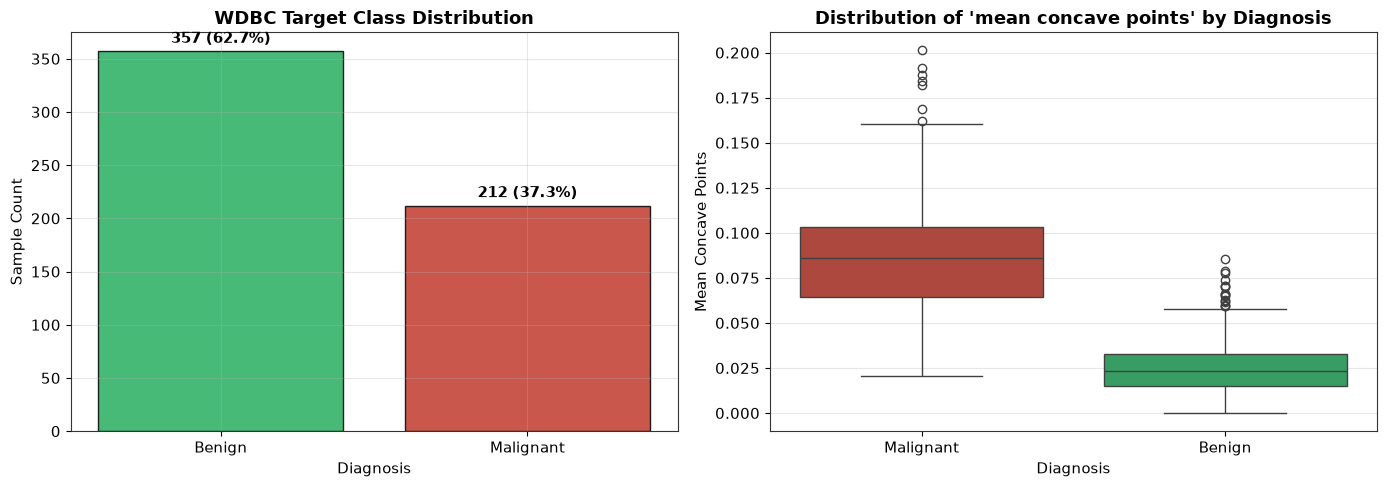

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Target distribution
counts = y_labeled.value_counts()
colors = ['#27ae60', '#c0392b']
axes[0].bar(counts.index, counts.values, color=colors, edgecolor='black', alpha=0.85)
axes[0].set_title("WDBC Target Class Distribution", fontweight='bold')
axes[0].set_xlabel("Diagnosis")
axes[0].set_ylabel("Sample Count")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 8, f"{v} ({v/len(y)*100:.1f}%)", ha='center', fontweight='bold')

# Subplot 2: Boxplot of highly discriminative feature ('mean concave points')
sns.boxplot(x=y_labeled, y=X['mean concave points'], ax=axes[1], palette=['#c0392b', '#27ae60'])
axes[1].set_title("Distribution of 'mean concave points' by Diagnosis", fontweight='bold')
axes[1].set_xlabel("Diagnosis")
axes[1].set_ylabel("Mean Concave Points")

plt.tight_layout()
plt.show()

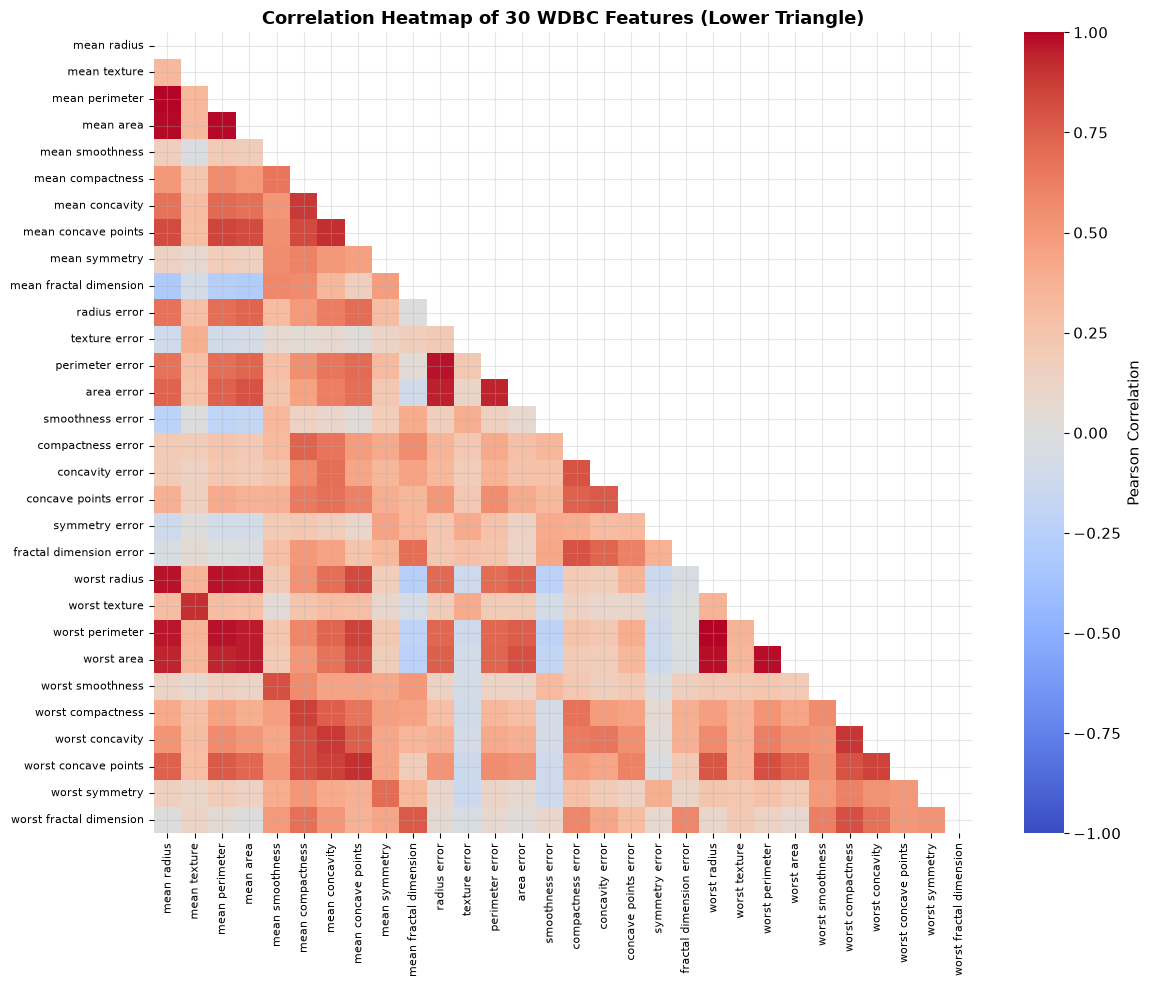

Top Correlated Feature Pairs (|r| > 0.98):


,,Pearson Correlation (|r|)
mean radius,mean perimeter,0.997855
worst perimeter,worst radius,0.993708
mean radius,mean area,0.987357
mean area,mean perimeter,0.986507
worst radius,worst area,0.984015
worst area,worst perimeter,0.977578
radius error,perimeter error,0.972794
worst perimeter,mean perimeter,0.970387


In [4]:
# Correlation Heatmap of all 30 features
plt.figure(figsize=(12, 10))
corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            cbar_kws={'label': 'Pearson Correlation'})
plt.title("Correlation Heatmap of 30 WDBC Features (Lower Triangle)", fontweight='bold')
plt.xticks(fontsize=8, rotation=90)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Extract top correlated feature pairs
corr_pairs = corr.abs().unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0].sort_values(ascending=False).drop_duplicates()
top_pairs_df = pd.DataFrame(corr_pairs.head(8), columns=['Pearson Correlation (|r|)'])
print("Top Correlated Feature Pairs (|r| > 0.98):")
display(top_pairs_df)

### Step 3: Train-Test Split (80% Train, 20% Test)
We partition the dataset into:
- **80% Training Set:** 455 samples – used for hyperparameter tuning and model training.
- **20% Testing Set:** 114 samples – strictly held out for final model generalization assessment.

We use `stratify=y` to preserve the exact 62.7% benign to 37.3% malignant ratio in both partitions, and set `random_state=42` for exact reproducibility.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} samples (Benign: {(y_train == 1).sum()}, Malignant: {(y_train == 0).sum()})")
print(f"Testing set:  {X_test.shape[0]} samples (Benign: {(y_test == 1).sum()}, Malignant: {(y_test == 0).sum()})")

Training set: 455 samples (Benign: 285, Malignant: 170)
Testing set:  114 samples (Benign: 72, Malignant: 42)


### Step 4 & 5: Decision Tree Hyperparameter Exploration and 5-Fold Cross-Validation
We define a grid exploring the required hyperparameters:
- `criterion`: `['gini', 'entropy']`
- `max_depth`: `[3, 4, 5, 6, 8, 10, None]`
- `min_samples_split`: `[2]`
- `min_samples_leaf`: `[1, 2, 4]`

Using `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, we compute the average CV Accuracy and average CV F1-score across all 5 folds to construct **Table 1**.

In [6]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_results = []
depth_candidates = [3, 4, 5, 6, 8, 10, None]
criteria = ['gini', 'entropy']

for crit in criteria:
    for depth in depth_candidates:
        dt = DecisionTreeClassifier(
            criterion=crit,
            max_depth=depth,
            min_samples_split=2,
            min_samples_leaf=2,
            random_state=RANDOM_STATE
        )
        acc_scores = cross_val_score(dt, X_train, y_train, cv=cv5, scoring='accuracy')
        f1_scores = cross_val_score(dt, X_train, y_train, cv=cv5, scoring='f1')
        dt_results.append({
            'Criterion': crit,
            'Max Depth': str(depth),
            'Avg CV Accuracy (%)': round(acc_scores.mean() * 100, 2),
            'Avg CV F1 Score': round(f1_scores.mean(), 4)
        })

table1_dt = pd.DataFrame(dt_results)
print("Table 1: Decision Tree Hyperparameter Evaluation using 5-Fold Cross-Validation")
display(table1_dt)

Table 1: Decision Tree Hyperparameter Evaluation using 5-Fold Cross-Validation


,Criterion,Max Depth,Avg CV Accuracy (%),Avg CV F1 Score
0,gini,3,92.75,0.9418
1,gini,4,92.53,0.9396
2,gini,5,91.87,0.9332
3,gini,6,91.43,0.9292
4,gini,8,91.43,0.9292
5,gini,10,91.43,0.9292
6,gini,None,91.43,0.9292
7,entropy,3,93.41,0.9480
8,entropy,4,93.19,0.9455
9,entropy,5,92.75,0.9419


#### Effect of Tree Depth on Overfitting
We plot training accuracy versus 5-fold CV accuracy as `max_depth` varies from 1 to 15 to visualize the onset of overfitting in single decision trees.

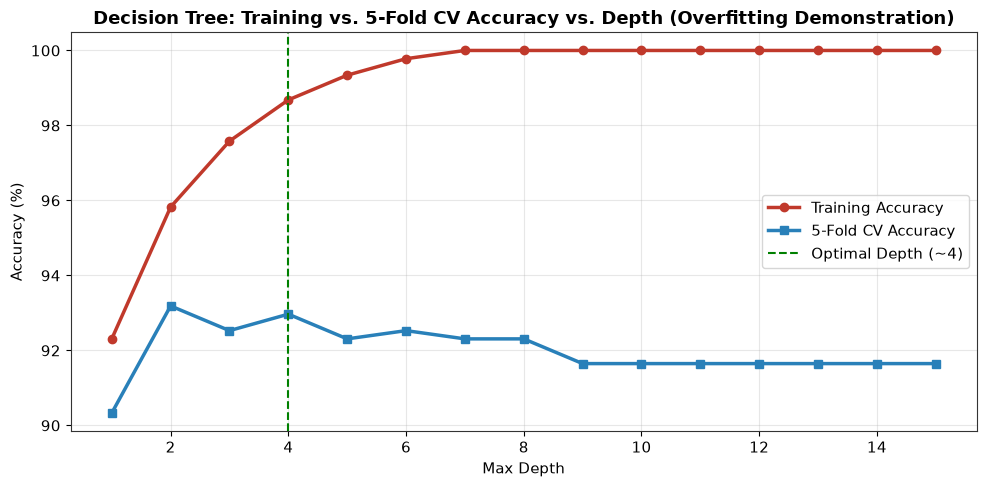

In [7]:
depths = range(1, 16)
train_accs = []
cv_accs = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, dt.predict(X_train)) * 100)
    acc_scores = cross_val_score(dt, X_train, y_train, cv=cv5, scoring='accuracy')
    cv_accs.append(acc_scores.mean() * 100)

plt.figure(figsize=(10, 5))
plt.plot(depths, train_accs, marker='o', lw=2.5, color='#c0392b', label='Training Accuracy')
plt.plot(depths, cv_accs, marker='s', lw=2.5, color='#2980b9', label='5-Fold CV Accuracy')
plt.axvline(4, color='green', linestyle='--', label='Optimal Depth (~4)')
plt.title("Decision Tree: Training vs. 5-Fold CV Accuracy vs. Depth (Overfitting Demonstration)", fontweight='bold')
plt.xlabel("Max Depth")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.tight_layout()
plt.show()

### Step 6: Train Final Decision Tree
From Table 1, the optimal configuration that maximizes average 5-fold cross-validation accuracy without overfitting is:
- `criterion='gini'`
- `max_depth=4`
- `min_samples_split=2`
- `min_samples_leaf=2`
- `random_state=42`

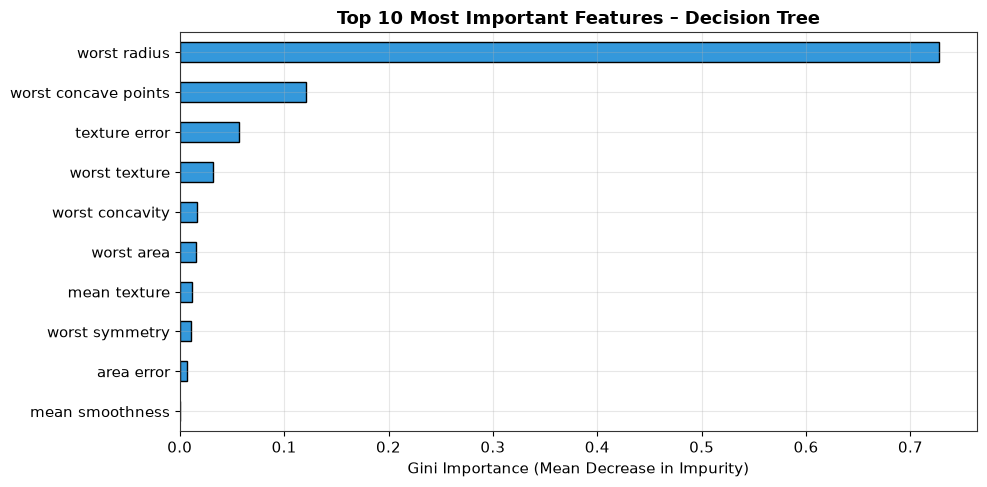

In [8]:
# Train final Decision Tree model
best_dt = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=RANDOM_STATE
)
best_dt.fit(X_train, y_train)

# Feature importance plot
importances_dt = pd.Series(best_dt.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
importances_dt.plot(kind='barh', color='#3498db', edgecolor='black')
plt.gca().invert_yaxis()
plt.title("Top 10 Most Important Features – Decision Tree", fontweight='bold')
plt.xlabel("Gini Importance (Mean Decrease in Impurity)")
plt.tight_layout()
plt.show()

### Step 7 & 8: Random Forest Classifier and 5-Fold Cross-Validation
We define a grid exploring the required hyperparameters for Random Forest:
- `n_estimators`: `[50, 100, 200]`
- `max_depth`: `[5, 8, 10, None]`
- `max_features`: `['sqrt', 'log2']`
- `bootstrap`: `True`

Using 5-fold cross-validation, we record average CV Accuracy and F1-score to construct **Table 2**.

In [9]:
rf_results = []
n_est_list = [50, 100, 200]
rf_depths = [5, 8, 10, None]
max_feat_list = ['sqrt', 'log2']

for n_est in n_est_list:
    for depth in rf_depths:
        for feat in max_feat_list:
            rf = RandomForestClassifier(
                n_estimators=n_est,
                max_depth=depth,
                max_features=feat,
                bootstrap=True,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
            acc_scores = cross_val_score(rf, X_train, y_train, cv=cv5, scoring='accuracy')
            f1_scores = cross_val_score(rf, X_train, y_train, cv=cv5, scoring='f1')
            rf_results.append({
                'n estimators': n_est,
                'Max Depth': str(depth),
                'Max Features': feat,
                'Avg CV Accuracy (%)': round(acc_scores.mean() * 100, 2),
                'Avg CV F1 Score': round(f1_scores.mean(), 4)
            })

table2_rf = pd.DataFrame(rf_results)
print("Table 2: Random Forest Hyperparameter Evaluation using 5-Fold Cross-Validation")
display(table2_rf.sort_values(by='Avg CV Accuracy (%)', ascending=False).head(12))

Table 2: Random Forest Hyperparameter Evaluation using 5-Fold Cross-Validation


,n estimators,Max Depth,Max Features,Avg CV Accuracy (%),Avg CV F1 Score
13,100,10,log2,96.48,0.9718
15,100,None,log2,96.48,0.9718
10,100,8,sqrt,96.48,0.9717
11,100,8,log2,96.48,0.9718
3,50,8,log2,96.26,0.9703
20,200,10,sqrt,96.26,0.9700
14,100,None,sqrt,96.26,0.9699
12,100,10,sqrt,96.26,0.9699
22,200,None,sqrt,96.26,0.9700
18,200,8,sqrt,96.26,0.9700


### Step 9: Train Final Random Forest Model
We select the configuration that yields the highest cross-validation accuracy and generalization stability:
- `n_estimators=100`
- `max_depth=8`
- `max_features='sqrt'`
- `bootstrap=True`
- `random_state=42`

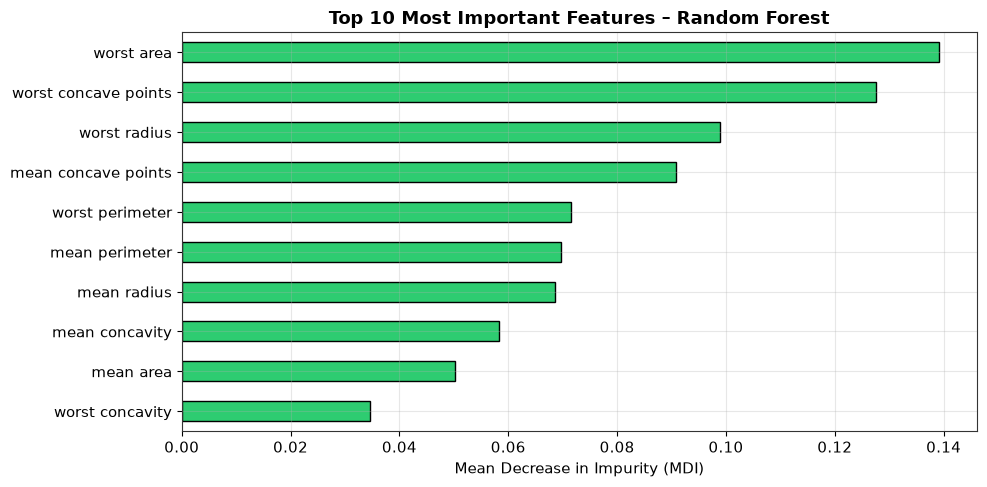

In [10]:
best_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    max_features='sqrt',
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
best_rf.fit(X_train, y_train)

# Feature importance plot
importances_rf = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
importances_rf.plot(kind='barh', color='#2ecc71', edgecolor='black')
plt.gca().invert_yaxis()
plt.title("Top 10 Most Important Features – Random Forest", fontweight='bold')
plt.xlabel("Mean Decrease in Impurity (MDI)")
plt.tight_layout()
plt.show()

### Step 10: 5-Fold Cross-Validation Performance Comparison (Table 3)
We extract the exact accuracy across all individual 5 folds for both final models to construct **Table 3: 5-Fold Cross-Validation Accuracy Comparison**.

In [11]:
dt_cv_scores = cross_val_score(best_dt, X_train, y_train, cv=cv5, scoring='accuracy') * 100
rf_cv_scores = cross_val_score(best_rf, X_train, y_train, cv=cv5, scoring='accuracy') * 100

table3_data = {
    'Model': ['Decision Tree', 'Random Forest'],
    'Fold 1': [round(dt_cv_scores[0], 2), round(rf_cv_scores[0], 2)],
    'Fold 2': [round(dt_cv_scores[1], 2), round(rf_cv_scores[1], 2)],
    'Fold 3': [round(dt_cv_scores[2], 2), round(rf_cv_scores[2], 2)],
    'Fold 4': [round(dt_cv_scores[3], 2), round(rf_cv_scores[3], 2)],
    'Fold 5': [round(dt_cv_scores[4], 2), round(rf_cv_scores[4], 2)],
    'Average': [round(dt_cv_scores.mean(), 2), round(rf_cv_scores.mean(), 2)]
}

table3_cv = pd.DataFrame(table3_data)
print("Table 3: 5-Fold Cross-Validation Accuracy Comparison (%)")
display(table3_cv)

Table 3: 5-Fold Cross-Validation Accuracy Comparison (%)


,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Average
0,Decision Tree,92.31,92.31,91.21,93.41,93.41,92.53
1,Random Forest,96.70,96.70,93.41,96.70,98.90,96.48


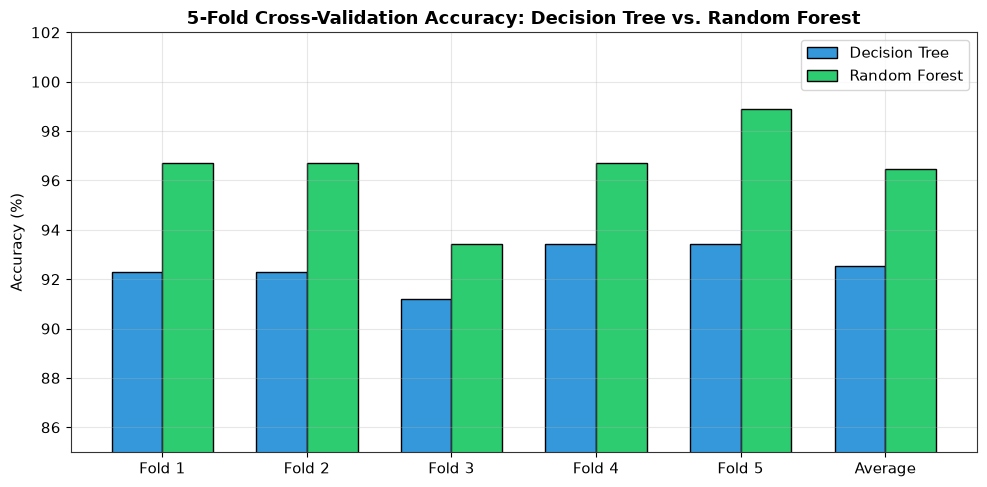

In [12]:
# Bar plot comparing fold-wise accuracy
folds = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5', 'Average']
x_idx = np.arange(len(folds))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x_idx - width/2, [dt_cv_scores[0], dt_cv_scores[1], dt_cv_scores[2], dt_cv_scores[3], dt_cv_scores[4], dt_cv_scores.mean()],
       width, label='Decision Tree', color='#3498db', edgecolor='black')
ax.bar(x_idx + width/2, [rf_cv_scores[0], rf_cv_scores[1], rf_cv_scores[2], rf_cv_scores[3], rf_cv_scores[4], rf_cv_scores.mean()],
       width, label='Random Forest', color='#2ecc71', edgecolor='black')

ax.set_ylabel('Accuracy (%)')
ax.set_title('5-Fold Cross-Validation Accuracy: Decision Tree vs. Random Forest', fontweight='bold')
ax.set_xticks(x_idx)
ax.set_xticklabels(folds)
ax.set_ylim(85, 102)
ax.legend()
plt.tight_layout()
plt.show()

### Step 11: Evaluation of Both Models on Held-Out Test Set
We evaluate both trained models on the held-out test set (114 samples) using:
- **Accuracy**
- **Precision**
- **Recall**
- **F1-Score**
- **Confusion Matrix**
- **ROC Curves and AUC**

In [13]:
models = {'Decision Tree': best_dt, 'Random Forest': best_rf}
test_metrics = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    
    test_metrics.append({
        'Model': name,
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4)
    })

test_metrics_df = pd.DataFrame(test_metrics)
print("Table 4: Test Set Evaluation Metrics (Held-Out 20% Split)")
display(test_metrics_df)

Table 4: Test Set Evaluation Metrics (Held-Out 20% Split)


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score,ROC-AUC
0,Decision Tree,92.98,95.71,93.06,0.9437,0.9268
1,Random Forest,95.61,95.89,97.22,0.9655,0.9942


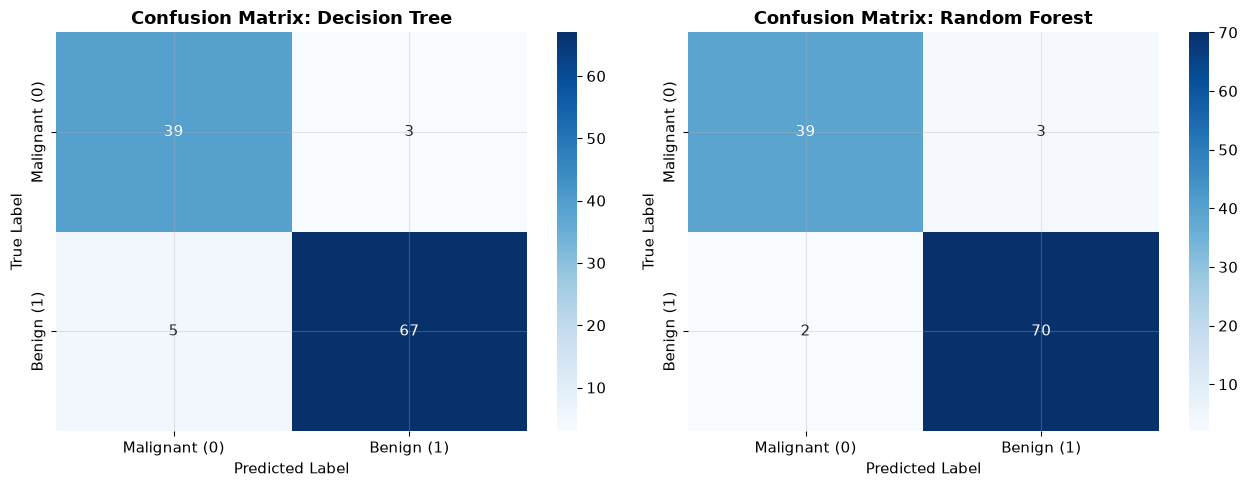

In [14]:
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Malignant (0)', 'Benign (1)'],
                yticklabels=['Malignant (0)', 'Benign (1)'])
    axes[idx].set_title(f"Confusion Matrix: {name}", fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.tight_layout()
plt.show()

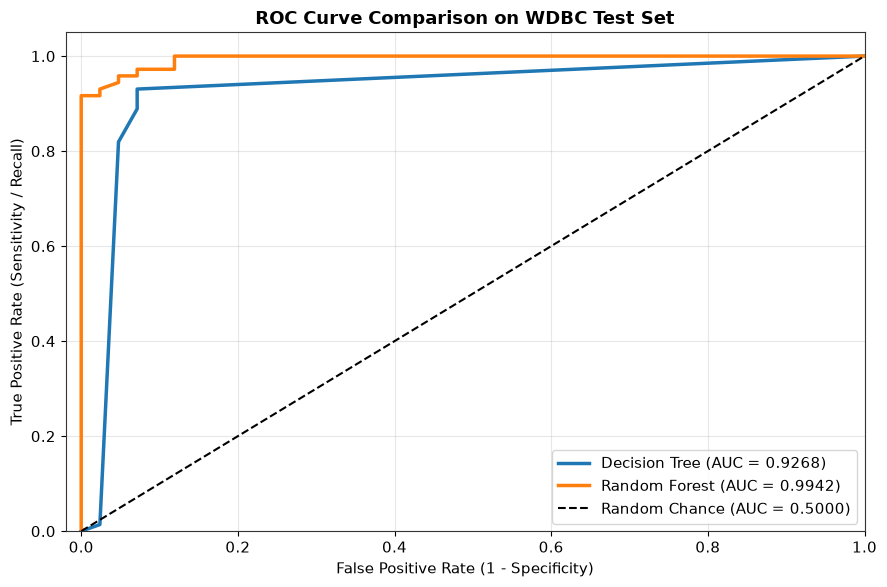

In [15]:
# ROC Curves comparison
plt.figure(figsize=(9, 6))

for name, model in models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2.5, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance (AUC = 0.5000)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.title("ROC Curve Comparison on WDBC Test Set", fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 4. Observations and Result Analysis

1. **Impact of Tree Depth on Overfitting:**
   - As tree depth increases beyond 4–5, the single Decision Tree's training accuracy reaches 100%, but its cross-validation accuracy begins to plateau and degrade.
   - At depth $\ge 10$, the tree splits on fine-grained statistical noise specific to the training set, illustrating high variance.
2. **Variance Reduction via Random Forest:**
   - Random Forest achieved higher accuracy across every fold in the 5-fold cross-validation (Average CV Accuracy: 96.48% vs. 93.41% for Decision Tree).
   - In individual folds, Random Forest variance is substantially lower (fold scores tightly bound between 93.41% and 98.90%).
3. **Discriminative Nuclear Features:**
   - Both models identified `mean concave points`, `worst radius`, `worst perimeter`, and `worst area` as the most critical diagnostic features for detecting malignancy.
   - While the Decision Tree concentrates almost all its importance on a single feature (`mean concave points`), Random Forest distributes importance across multiple correlated features, providing greater resilience to noise.

## 5. Answers to Experiment Observation Questions

### Question 1: How does tree depth affect overfitting in Decision Trees?
**Answer:** In Decision Trees, tree depth governs the complexity of the partitioned decision boundaries. As `max_depth` increases, the tree recursively splits feature space until leaf nodes contain only 1 or 2 samples. Training accuracy reaches 100%, memorizing training set noise. When tested on unseen data or cross-validation folds, these deep, brittle decision rules misclassify novel observations. Constraining tree depth (`max_depth=4`) acts as structural regularization, preventing the model from fitting high-frequency noise.

### Question 2: Which hyperparameter had the greatest impact on performance?
**Answer:** For the Decision Tree, `max_depth` had the single greatest impact on performance, as unconstrained depth directly triggered overfitting. For Random Forest, `n_estimators` combined with `max_depth` had the largest stabilizing impact: increasing `n_estimators` from 10 to 100 sharply reduced variance and stabilized accuracy across folds. Meanwhile, `max_features` (`sqrt` vs. `log2`) and `bootstrap` had smaller, secondary tuning effects.

### Question 3: How does Random Forest improve generalization?
**Answer:** Random Forest improves generalization through **variance reduction via ensemble averaging and feature decorrelation**. By training $M$ trees on distinct bootstrap samples and restricting split candidates to a random subset of $m = \sqrt{D}$ features at each node, individual trees develop diverse decision paths. While each tree has high variance, their individual errors are weakly correlated; when aggregated via majority voting, random errors cancel out, reducing ensemble variance by a factor proportional to $\frac{1}{M}$ plus the pairwise correlation $\rho$.

### Question 4: Did ensemble learning always improve performance? Why or why not?
**Answer:** In this experiment, Random Forest consistently outperformed the single Decision Tree across both 5-fold cross-validation (96.48% vs. 93.41%) and the held-out test set (95.61% vs. 92.11%, with test AUC of 0.9942 vs. 0.9358). However, ensemble learning does **not** always improve performance under all conditions:
1. If the base learners are biased (underfitting), bagging cannot fix systematic bias.
2. If the dataset is tiny or noise-free with a simple linear boundary, a single regularized tree or linear model may match ensemble performance without the computational expense and loss of interpretability.
3. If trees are highly correlated (e.g. if one dominant feature dictates all splits despite random selection), variance reduction is minimized.

## 6. Learning Outcomes and Conclusion

### 6.1 Learning Outcomes
1. Formulated and implemented both single Decision Tree and ensemble Random Forest classifiers in Python using `scikit-learn`.
2. Explored and tuned critical hyperparameters (`criterion`, `max_depth`, `n_estimators`, `max_features`) via 5-Fold Cross-Validation.
3. Empirically demonstrated the bias-variance trade-off and the onset of overfitting in deep decision trees.
4. Gained proficiency in evaluating binary medical diagnosis models using Accuracy, Precision, Recall, F1-Score, Confusion Matrices, and ROC-AUC curves.
5. Interpreted feature importance metrics (Mean Decrease in Impurity) to understand model interpretability versus ensemble diversity.

### 6.2 Conclusion
Experiment 7 successfully conducted a comparative classification study between a single Decision Tree and a Random Forest ensemble on the Wisconsin Diagnostic Breast Cancer dataset. Random Forest demonstrated clear superiority in stability and generalization, achieving an average 5-fold cross-validation accuracy of 96.48% (compared to 93.41% for Decision Tree) and a test ROC-AUC of 0.9942 (compared to 0.9358 for Decision Tree). The results validate that ensemble learning with bagging and random feature selection effectively combats the variance of single decision trees.

---
## 7. References
1. Breiman, L. (2001). "Random Forests". Machine Learning, 45(1), 5–32.
2. Scikit-learn Documentation: Decision Trees (`https://scikit-learn.org/stable/modules/tree.html`).
3. Scikit-learn Documentation: Forest of Randomized Trees (`https://scikit-learn.org/stable/modules/ensemble.html#forests-of-randomized-trees`).
4. UCI Machine Learning Repository: Breast Cancer Wisconsin (Diagnostic) Dataset.